# Week 6 — Next-Day Rain Classification in Kathmandu (MLP vs LSTM vs 1D-CNN)

**Task:** binary classification — given the last 14 days of weather at Tribhuvan International Airport (TIA), Kathmandu, predict whether it will **rain tomorrow** (`precipitation > 0`).

**Dataset:** Kathmandu Weather Data 2015–2025 (Kaggle: `shaswotp84/kathmandu-weather-data-20152025`) → https://www.kaggle.com/datasets/shaswotp84/kathmandu-weather-data-20152025  
File: `TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30.csv` (3,468 daily rows). **Ground truth** = the observed `precipitation` value of the following day.

**Models (3 distinct architectures, all PyTorch):**
| Model | Family | Input |
|---|---|---|
| MLP | Feed-forward neural network | 14-day window flattened to one vector |
| LSTM | Deep recurrent network | 14-day sequence |
| 1D-CNN | Deep convolutional network | 14-day sequence |

**Metrics:** Precision, Recall, F1, Accuracy, ROC-AUC, confusion matrix and ROC curves on a held-out chronological test year.

## 1. Imports, configuration and reproducibility

In [1]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)

# Look for the CSV in the usual places (same folder as the notebook, Colab, etc.)
CSV_NAME = "TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30.csv"
CANDIDATES = [CSV_NAME, f"/content/{CSV_NAME}", f"/mnt/user-data/uploads/{CSV_NAME}", f"../{CSV_NAME}"]
CSV = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert CSV is not None, f"Put {CSV_NAME} next to this notebook."

OUT = "week6_outputs"; os.makedirs(OUT, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Data file:", CSV)
print("Device   :", device)

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Data file: TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30.csv
Device   : mps


## 2. Load data and quick exploration

In [2]:
raw = pd.read_csv(CSV, parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)
print("Shape:", raw.shape, "| Range:", raw["datetime"].min().date(), "->", raw["datetime"].max().date())
raw.head()

Shape: (3468, 22) | Range: 2015-01-01 -> 2025-06-30


,datetime,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,preciptype,windgust,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,sunrise,sunset,precipitation
0,2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,rain,11.2,...,1020.4,79.1,2.4,96.6,8.3,4,NaN,2015-01-01T06:54:15,2015-01-01T17:19:31,0.8
1,2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,rain,19.9,...,1022.2,93.3,2.9,40.4,3.3,2,NaN,2015-01-02T06:54:31,2015-01-02T17:20:12,0.0
2,2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,rain,15.4,...,1021.0,90.3,2.8,58.6,5.0,4,NaN,2015-01-03T06:54:46,2015-01-03T17:20:54,0.5
3,2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,rain,17.0,...,1018.1,67.1,2.7,118.0,10.3,6,NaN,2015-01-04T06:54:58,2015-01-04T17:21:37,0.5
4,2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,NaN,16.3,...,1013.9,41.6,3.9,139.2,12.0,6,NaN,2015-01-05T06:55:10,2015-01-05T17:22:20,0.0


In [3]:
# Calendar gaps: the series has a 12-month hole (Jul 2015 - Jun 2016)
gap_days = raw["datetime"].diff().dt.days
print("Day-to-day intervals:", gap_days.value_counts().to_dict())
g = raw.loc[gap_days > 1]
print("Gap starts after", raw.loc[g.index - 1, "datetime"].iloc[0].date(), "and resumes on", g["datetime"].iloc[0].date())
print("\nMissing values (top):")
print(raw.isnull().sum().sort_values(ascending=False).head(4))

Day-to-day intervals: {1.0: 3466, 367.0: 1}
Gap starts after 2015-06-30 and resumes on 2016-07-01

Missing values (top):
severerisk          2633
preciptype          1925
datetime               0
sealevelpressure       0
dtype: int64


## 3. Cleaning, feature engineering and target
* Fix sensor errors (`windspeed` > 2× `windgust`; one absurd `visibility` value).
* Cyclical calendar features, daylight hours, temperature range, lag / rolling features.
* **Lag / rolling features are blanked across the 2015–16 gap** so nothing links days that are 12 months apart.
* **Target** `rain_next` = 1 if `precipitation` on the *next* day is > 0.
* Only data after the gap (from 2016-07-01) is used, so every sample is a clean continuous sequence.

In [4]:
df = raw.copy()

# --- sensor outliers ---
bad = df["windspeed"] > df["windgust"] * 2
df.loc[bad, "windspeed"] = df.loc[bad, "windgust"] * 0.6
df.loc[df["visibility"] > 20, "visibility"] = df["visibility"].median()

# --- calendar / seasonal features ---
df["month"] = df["datetime"].dt.month
df["day_of_year"] = df["datetime"].dt.dayofyear
df["month_sin"], df["month_cos"] = np.sin(2*np.pi*df["month"]/12), np.cos(2*np.pi*df["month"]/12)
df["doy_sin"],   df["doy_cos"]   = np.sin(2*np.pi*df["day_of_year"]/365), np.cos(2*np.pi*df["day_of_year"]/365)

# --- physical / derived features ---
df["sunrise"], df["sunset"] = pd.to_datetime(df["sunrise"]), pd.to_datetime(df["sunset"])
df["daylight_hours"] = (df["sunset"] - df["sunrise"]).dt.total_seconds() / 3600
df["rained"]     = (df["precipitation"] > 0).astype(int)      # TODAY's rain (known at prediction time)
df["temp_range"] = df["tempmax"] - df["tempmin"]

# --- lag / rolling features (invalid across calendar gaps) ---
after_gap = df["datetime"].diff().dt.days != 1
df["temp_lag1"]     = df["temp"].shift(1)
df["humidity_lag1"] = df["humidity"].shift(1)
df["temp_roll7"]    = df["temp"].shift(1).rolling(7, min_periods=3).mean()
df.loc[after_gap, ["temp_lag1", "humidity_lag1", "temp_roll7"]] = np.nan

# --- target: does it rain TOMORROW? ---
df["rain_next"] = (df["precipitation"].shift(-1) > 0).astype(float)
next_is_gap = df["datetime"].diff(-1).dt.days.abs() != 1
df.loc[next_is_gap | df["precipitation"].shift(-1).isna(), "rain_next"] = np.nan

FEATURES = ["temp", "temp_range", "humidity", "dew", "sealevelpressure", "cloudcover",
            "visibility", "solarradiation", "windspeed", "windgust", "precipprob",
            "month_sin", "month_cos", "doy_sin", "doy_cos", "daylight_hours", "rained",
            "temp_lag1", "humidity_lag1", "temp_roll7"]

data = df[(df["datetime"] >= "2016-07-01") & df["rain_next"].notna()].dropna(subset=FEATURES).reset_index(drop=True)
data["rain_next"] = data["rain_next"].astype(int)
print(f"Usable days: {len(data)} | features: {len(FEATURES)} | tomorrow-rain rate: {data['rain_next'].mean():.3f}")

Usable days: 3285 | features: 20 | tomorrow-rain rate: 0.395


### 3.1 Class balance and seasonality

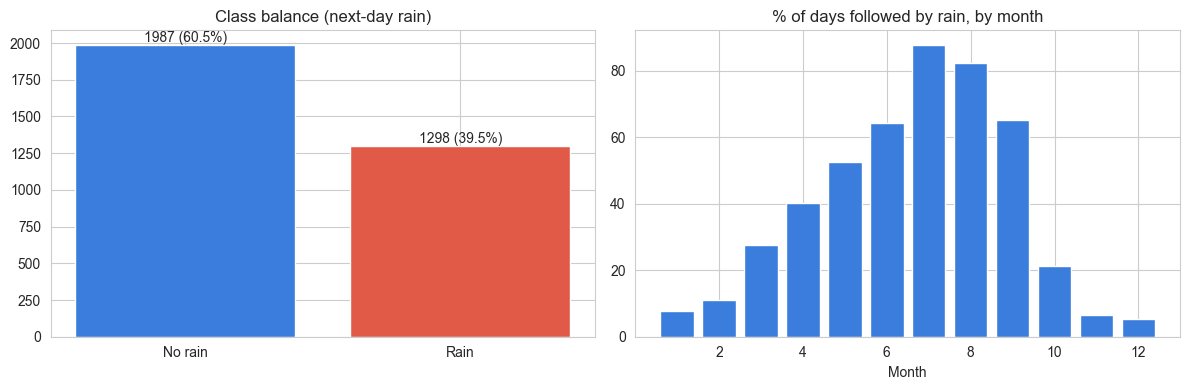

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cnt = data["rain_next"].value_counts().sort_index()
ax[0].bar(["No rain", "Rain"], cnt.values, color=["#3b7ddd", "#e05a47"])
for i, v in enumerate(cnt.values): ax[0].text(i, v + 20, f"{v} ({v/len(data):.1%})", ha="center")
ax[0].set_title("Class balance (next-day rain)")

mr = data.groupby(data["datetime"].dt.month)["rain_next"].mean() * 100
ax[1].bar(mr.index, mr.values, color="#3b7ddd")
ax[1].set_title("% of days followed by rain, by month"); ax[1].set_xlabel("Month")
plt.tight_layout(); plt.savefig(f"{OUT}/01_class_balance_seasonality.png", dpi=130); plt.show()

## 4. Chronological split, scaling and 14-day windows

A **time-based split** is used because this is a time series (random splitting would leak the future into training):

| Split | Period |
|---|---|
| Train | 2016-07-01 → 2023-06-30 |
| Validation | 2023-07-01 → 2024-06-30 |
| Test | 2024-07-01 → 2025-06-30 |

Each sample is **14 consecutive days of features** (days *t-13 … t*) and its label is **whether it rains on day *t+1***. The `StandardScaler` is fitted on the training period only.  
Windows that would straddle a calendar gap are discarded.

In [6]:
WINDOW = 14
SPLITS = {"train": ("2016-07-01", "2023-06-30"),
          "val":   ("2023-07-01", "2024-06-30"),
          "test":  ("2024-07-01", "2025-06-30")}

# Scaler fitted on training rows only (no leakage)
tr0, tr1 = map(pd.Timestamp, SPLITS["train"])
scaler = StandardScaler().fit(data.loc[data["datetime"].between(tr0, tr1), FEATURES])
X_all = scaler.transform(data[FEATURES]).astype(np.float32)
y_all = data["rain_next"].values.astype(np.int64)
dates = data["datetime"].values.astype("datetime64[D]")

def make_windows(d0, d1):
    """Window = days t-13..t  ->  label = rain on day t+1 (date of the *prediction target* must fall in [d0, d1])."""
    d0, d1 = pd.Timestamp(d0), pd.Timestamp(d1)
    X, y = [], []
    for t in range(WINDOW - 1, len(X_all)):
        span = (dates[t] - dates[t - WINDOW + 1]).astype(int)
        if span != WINDOW - 1:                       # window crosses a calendar gap
            continue
        target_day = pd.Timestamp(dates[t]) + pd.Timedelta(days=1)
        if not (d0 <= target_day <= d1):
            continue
        X.append(X_all[t - WINDOW + 1: t + 1]); y.append(y_all[t])
    return np.stack(X), np.array(y)

Xtr, ytr = make_windows(*SPLITS["train"])
Xva, yva = make_windows(*SPLITS["val"])
Xte, yte = make_windows(*SPLITS["test"])
for n, X, y in [("Train", Xtr, ytr), ("Val", Xva, yva), ("Test", Xte, yte)]:
    print(f"{n:5s}: X {X.shape}  y {y.shape}  rain rate {y.mean():.3f}")
N_FEAT = Xtr.shape[2]

Train: X (2541, 14, 20)  y (2541,)  rain rate 0.389
Val  : X (366, 14, 20)  y (366,)  rain rate 0.385
Test : X (365, 14, 20)  y (365,)  rain rate 0.430


In [7]:
# Sanity check against label leakage: the label day (t+1) must NOT be inside the input window.
t = 500
sample_dates = dates[t - WINDOW + 1: t + 1]
print("Window days :", sample_dates[0], "->", sample_dates[-1])
print("Label day   :", dates[t] + np.timedelta64(1, "D"), "(strictly after the window)")

Window days : 2017-11-01 -> 2017-11-14
Label day   : 2017-11-15 (strictly after the window)


## 5. Model definitions

All three models output **2 logits** (No rain / Rain) and are trained with cross-entropy.

In [8]:
class MLP(nn.Module):
    """Feed-forward neural network on the flattened 14-day window."""
    def __init__(self, n_feat, window=WINDOW, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers, d = [nn.Flatten()], n_feat * window
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)


class LSTMClf(nn.Module):
    """Recurrent deep model: last hidden state of a (stacked) LSTM -> classifier."""
    def __init__(self, n_feat, hidden=64, layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 2)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.fc(self.drop(h[-1]))


class CNN1D(nn.Module):
    """Convolutional deep model: 1D convolutions slide along the time axis."""
    def __init__(self, n_feat, channels=64, dropout=0.3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_feat, channels, kernel_size=3, padding=1), nn.BatchNorm1d(channels), nn.ReLU(),
            nn.Conv1d(channels, channels, kernel_size=3, padding=1), nn.BatchNorm1d(channels), nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(channels, 2)
    def forward(self, x):                      # x: (batch, time, feat) -> (batch, feat, time)
        z = self.conv(x.transpose(1, 2))
        return self.fc(self.drop(self.pool(z).squeeze(-1)))


MODELS = {
    "MLP":     lambda: MLP(N_FEAT),
    "LSTM":    lambda: LSTMClf(N_FEAT),
    "1D-CNN":  lambda: CNN1D(N_FEAT),
}
for n, f in MODELS.items():
    m = f(); print(f"{n:7s} parameters: {sum(p.numel() for p in m.parameters()):,}")

MLP     parameters: 44,738
LSTM    parameters: 55,426
1D-CNN  parameters: 16,642


## 6. Training and evaluation utilities
* **Adam** + weight decay, **class-weighted cross-entropy** (rain is the minority class, ~40 %).
* Validation loss after every epoch; the **best-validation-loss weights are restored** (early stopping, patience = 8).
* Predictions: class = argmax; `P(rain)` = softmax probability, used for ROC-AUC.

In [9]:
def loader(X, y, batch=64, shuffle=False):
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)), batch_size=batch, shuffle=shuffle)

@torch.no_grad()
def predict(model, X, y, batch=256):
    model.eval()
    probs, losses = [], 0.0
    ce = nn.CrossEntropyLoss(reduction="sum")
    for xb, yb in loader(X, y, batch):
        out = model(xb.to(device))
        losses += ce(out, yb.to(device)).item()
        probs.append(out.softmax(1)[:, 1].cpu().numpy())
    return np.concatenate(probs), losses / len(y)

def train_model(name, seed=SEED, epochs=60, patience=8, lr=1e-3, wd=1e-3, verbose=True):
    set_seed(seed)
    model = MODELS[name]().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    w = torch.tensor([1.0, (ytr == 0).sum() / (ytr == 1).sum()], dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    tr_loader = loader(Xtr, ytr, shuffle=True)

    hist = {"loss": [], "val_loss": [], "val_auc": []}
    best_loss, best_state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            run += loss.item() * len(xb)
        p_val, v_loss = predict(model, Xva, yva)
        hist["loss"].append(run / len(ytr)); hist["val_loss"].append(v_loss)
        hist["val_auc"].append(roc_auc_score(yva, p_val))
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"[{name}] ep{ep:02d} train_loss {hist['loss'][-1]:.4f} | val_loss {v_loss:.4f} | val_AUC {hist['val_auc'][-1]:.3f}")
        if v_loss < best_loss - 1e-4:
            best_loss, bad = v_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"[{name}] early stop at epoch {ep} (best val_loss {best_loss:.4f})")
                break
    model.load_state_dict(best_state)
    return model, hist

def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return dict(accuracy=accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0),
                f1=f1_score(y_true, pred, zero_division=0),
                auc=roc_auc_score(y_true, prob))

## 7. Train the three models

In [10]:
trained, histories, test_prob, val_prob = {}, {}, {}, {}
for name in MODELS:
    print("=" * 60)
    model, hist = train_model(name)
    trained[name], histories[name] = model, hist
    test_prob[name], _ = predict(model, Xte, yte)
    val_prob[name], _  = predict(model, Xva, yva)
    torch.save(model.state_dict(), f"{OUT}/{name.replace('-', '')}_best.pt")

[MLP] ep01 train_loss 0.5014 | val_loss 0.5548 | val_AUC 0.816
[MLP] ep05 train_loss 0.4236 | val_loss 0.5386 | val_AUC 0.828
[MLP] ep10 train_loss 0.3943 | val_loss 0.5287 | val_AUC 0.833
[MLP] early stop at epoch 14 (best val_loss 0.5089)
[LSTM] ep01 train_loss 0.5512 | val_loss 0.5412 | val_AUC 0.794
[LSTM] ep05 train_loss 0.4584 | val_loss 0.5094 | val_AUC 0.820
[LSTM] ep10 train_loss 0.4376 | val_loss 0.5088 | val_AUC 0.834
[LSTM] ep15 train_loss 0.4295 | val_loss 0.4865 | val_AUC 0.842
[LSTM] ep20 train_loss 0.4185 | val_loss 0.4836 | val_AUC 0.848
[LSTM] ep25 train_loss 0.4104 | val_loss 0.4795 | val_AUC 0.845
[LSTM] ep30 train_loss 0.4008 | val_loss 0.4816 | val_AUC 0.846
[LSTM] early stop at epoch 30 (best val_loss 0.4703)
[1D-CNN] ep01 train_loss 0.4948 | val_loss 0.5825 | val_AUC 0.786
[1D-CNN] ep05 train_loss 0.4569 | val_loss 0.6035 | val_AUC 0.799
[1D-CNN] early stop at epoch 9 (best val_loss 0.5825)


### 7.1 Learning curves

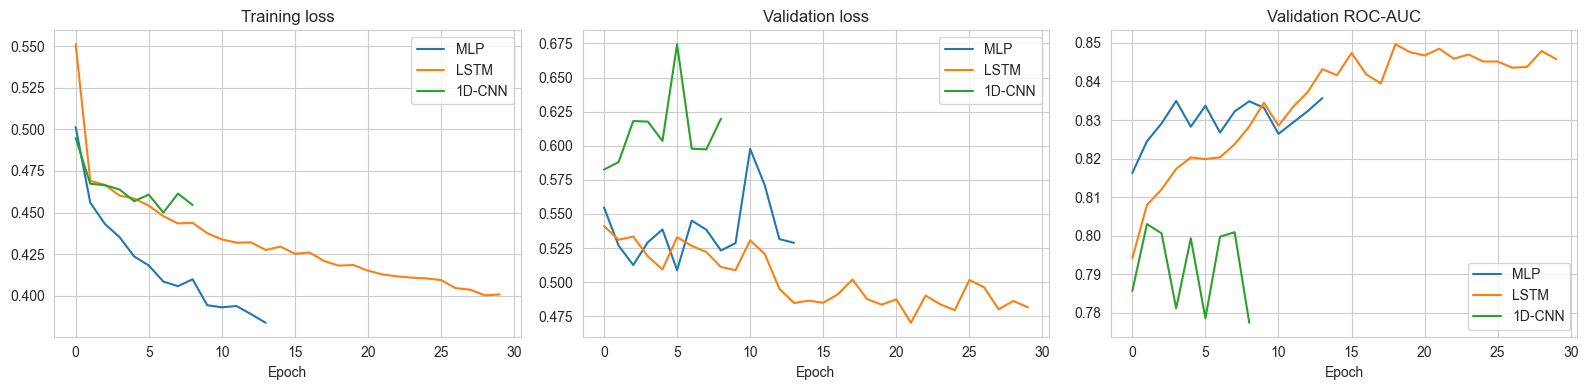

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n, h in histories.items():
    ax[0].plot(h["loss"], label=n); ax[1].plot(h["val_loss"], label=n); ax[2].plot(h["val_auc"], label=n)
for a, t in zip(ax, ["Training loss", "Validation loss", "Validation ROC-AUC"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/02_learning_curves.png", dpi=130); plt.show()

## 8. Test-set results (held-out year 2024-07 → 2025-06)

In [13]:
rows = {n: metrics(yte, p) for n, p in test_prob.items()}
res = pd.DataFrame(rows).T[["accuracy", "precision", "recall", "f1", "auc"]]
res.columns = ["Accuracy", "Precision (rain)", "Recall (rain)", "F1 (rain)", "ROC-AUC"]
print(f"Test samples: {len(yte)} | rain days: {yte.sum()} ({yte.mean():.1%}) | majority-class accuracy: {1-yte.mean():.3f} | chance AUC: 0.500")
res.round(3).style.highlight_max(axis=0, color="#cdeccd") 

Test samples: 365 | rain days: 157 (43.0%) | majority-class accuracy: 0.570 | chance AUC: 0.500


,Accuracy,Precision (rain),Recall (rain),F1 (rain),ROC-AUC
MLP,0.836000,0.813000,0.803000,0.808000,0.870000
LSTM,0.836000,0.813000,0.803000,0.808000,0.890000
1D-CNN,0.742000,0.657000,0.841000,0.737000,0.841000


In [14]:
for n, p in test_prob.items():
    print("=" * 55, f"\n{n}\n" + "=" * 55)
    print(classification_report(yte, (p >= 0.5).astype(int), target_names=["No rain", "Rain"], digits=3))

MLP
              precision    recall  f1-score   support

     No rain      0.852     0.861     0.856       208
        Rain      0.813     0.803     0.808       157

    accuracy                          0.836       365
   macro avg      0.833     0.832     0.832       365
weighted avg      0.835     0.836     0.835       365

LSTM
              precision    recall  f1-score   support

     No rain      0.852     0.861     0.856       208
        Rain      0.813     0.803     0.808       157

    accuracy                          0.836       365
   macro avg      0.833     0.832     0.832       365
weighted avg      0.835     0.836     0.835       365

1D-CNN
              precision    recall  f1-score   support

     No rain      0.848     0.668     0.747       208
        Rain      0.657     0.841     0.737       157

    accuracy                          0.742       365
   macro avg      0.752     0.755     0.742       365
weighted avg      0.765     0.742     0.743       365



### 8.1 Confusion matrices

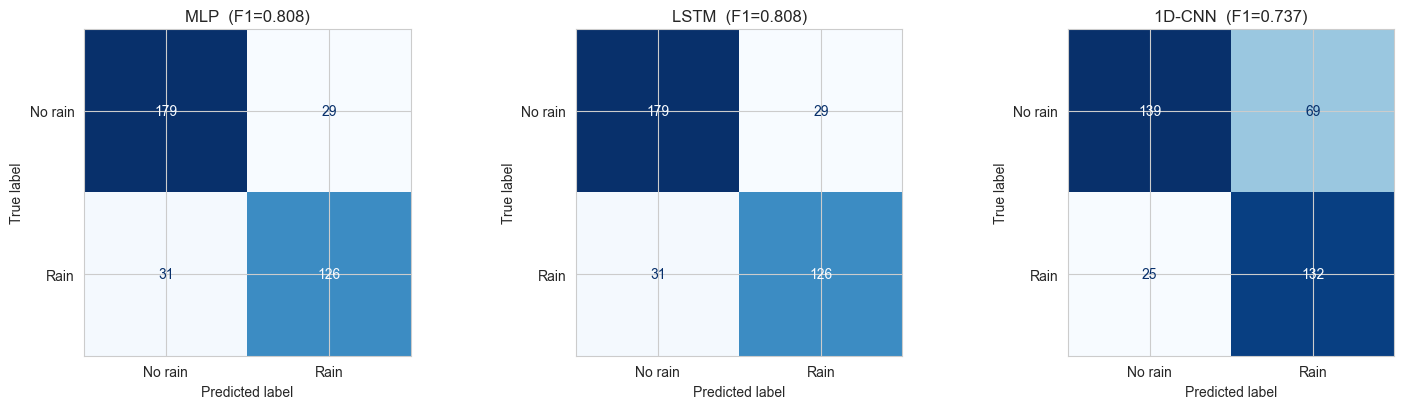

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (n, p) in zip(ax, test_prob.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte, (p >= 0.5).astype(int)),
                           display_labels=["No rain", "Rain"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{n}  (F1={res.loc[n, 'F1 (rain)']:.3f})")
plt.tight_layout(); plt.savefig(f"{OUT}/03_confusion_matrices.png", dpi=130); plt.show()

### 8.2 ROC curves and AUC

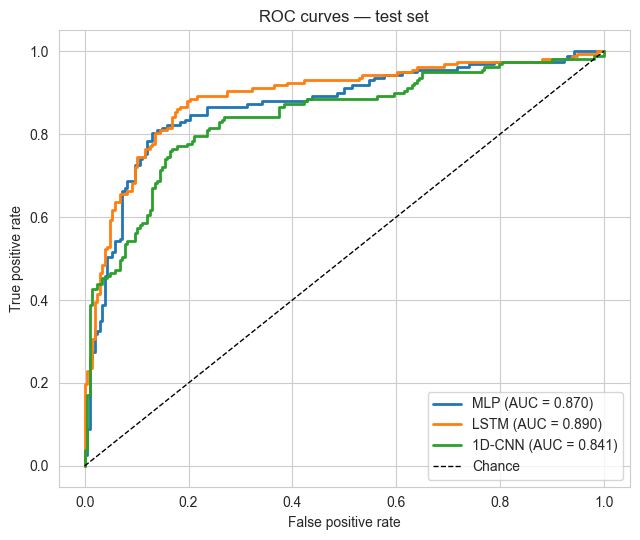

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for n, p in test_prob.items():
    fpr, tpr, _ = roc_curve(yte, p)
    ax.plot(fpr, tpr, lw=2, label=f"{n} (AUC = {roc_auc_score(yte, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/04_roc_curves.png", dpi=130); plt.show()

### 8.3 Metric comparison

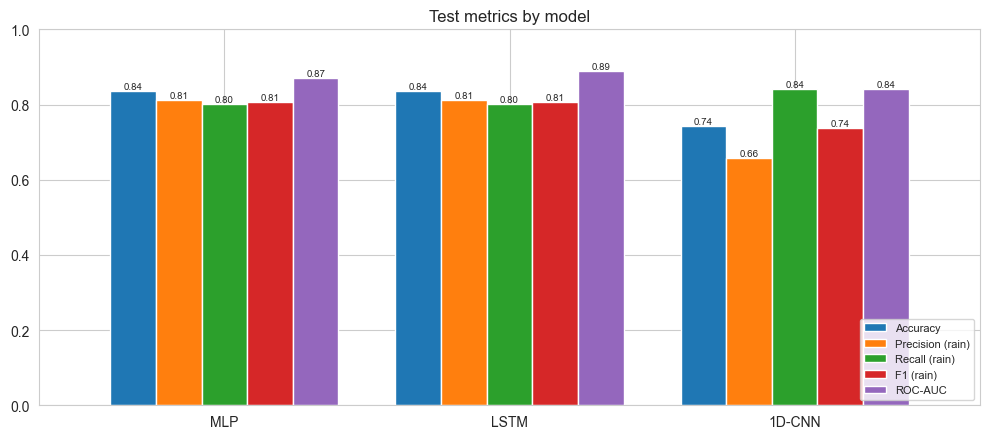

In [17]:
ax = res.plot(kind="bar", figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylim(0, 1); ax.set_title("Test metrics by model"); ax.legend(loc="lower right", fontsize=8)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/05_metric_comparison.png", dpi=130); plt.show()

## 9. Robustness check — 5 random seeds
A single training run can be lucky or unlucky (small dataset: ~360 test days). Each model is retrained with 5 different seeds; the table shows **mean ± std** on the test set.

In [18]:
SEEDS = [0, 1, 2, 3, 4]
runs = {n: [] for n in MODELS}
for n in MODELS:
    for s in SEEDS:
        m, _ = train_model(n, seed=s, verbose=False)
        p, _ = predict(m, Xte, yte)
        runs[n].append(metrics(yte, p))
    print("done:", n)

summary = pd.DataFrame({n: {k: f"{np.mean([r[k] for r in rs]):.3f} ± {np.std([r[k] for r in rs]):.3f}"
                            for k in ["accuracy", "precision", "recall", "f1", "auc"]}
                        for n, rs in runs.items()}).T
summary.columns = ["Accuracy", "Precision (rain)", "Recall (rain)", "F1 (rain)", "ROC-AUC"]
summary

done: MLP
done: LSTM
done: 1D-CNN


,Accuracy,Precision (rain),Recall (rain),F1 (rain),ROC-AUC
MLP,0.831 ± 0.005,0.808 ± 0.009,0.796 ± 0.015,0.802 ± 0.006,0.877 ± 0.005
LSTM,0.830 ± 0.009,0.795 ± 0.010,0.814 ± 0.011,0.804 ± 0.010,0.882 ± 0.007
1D-CNN,0.796 ± 0.023,0.752 ± 0.030,0.785 ± 0.033,0.768 ± 0.026,0.851 ± 0.010


## 10. Reload check — saved weights reproduce the results

In [19]:
reloaded = LSTMClf(N_FEAT).to(device)
reloaded.load_state_dict(torch.load(f"{OUT}/LSTM_best.pt", map_location=device))
p2, _ = predict(reloaded, Xte, yte)
print("Max probability difference after reload:", float(np.abs(p2 - test_prob["LSTM"]).max()))
print("Saved files:", sorted(os.listdir(OUT)))

Max probability difference after reload: 0.0
Saved files: ['01_class_balance_seasonality.png', '02_learning_curves.png', '03_confusion_matrices.png', '04_roc_curves.png', '05_metric_comparison.png', '1DCNN_best.pt', 'LSTM_best.pt', 'MLP_best.pt', 'demo_1dcnn_false_alarm.png', 'demo_monsoon_rain.png', 'demo_winter_dry.png']


## 11. Summary
The cell below prints the best model per metric from the results above, so the conclusions stay in sync with whatever the run produced.

In [20]:
print("Best model per metric (single run, seed 42):")
for col in res.columns:
    print(f"  {col:18s}: {res[col].idxmax():7s} ({res[col].max():.3f})")
print("\nBest model by 5-seed mean ROC-AUC:",
      max(runs, key=lambda n: np.mean([r['auc'] for r in runs[n]])))

Best model per metric (single run, seed 42):
  Accuracy          : MLP     (0.836)
  Precision (rain)  : MLP     (0.813)
  Recall (rain)     : 1D-CNN  (0.841)
  F1 (rain)         : MLP     (0.808)
  ROC-AUC           : LSTM    (0.890)

Best model by 5-seed mean ROC-AUC: LSTM
